In [1]:
import sys
import time
import itertools
import pandas as pd
import os
from pathlib import Path
import numpy as np
from typing import Union
import random
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, RocCurveDisplay
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
sys.path.insert(1, '..')
from Guidestar_model.DiscretisationFunctions import *
from utilsN.FPKM_functions import *

# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '..')


In [2]:
seed = 0
np.random.seed(seed)
random.seed(seed)
os.environ["PYTHONHASHSEED"] = str(seed)

In [3]:
import sklearn, numpy, joblib, sys
print(sklearn.__version__, numpy.__version__, joblib.__version__, sys.version)
print(joblib.effective_n_jobs(-3))

1.1.1 1.25.2 1.1.1 3.10.8 | packaged by conda-forge | (main, Nov 22 2022, 08:16:53) [MSC v.1929 64 bit (AMD64)]
6


In [4]:
# LIVER
GS_gene_list = ['Acly','Hnf4a','Pigr','Gpam']
blank_no = 7
blank_list = ['Blank' + str(i) for i in range(1,blank_no+1)]
cv_fold = 5
features_to_use = ['meaninten1_frob', 'mindist2_clipped', 'mindist3_clipped', 'size']
blank_ratio = None
merfish_ratio = 1
colocal_ratio = None
bft = 0.21
nfovs = 49

# checked that colocalization count is identical to github (21 Aug 2026)
GS_filepath = os.path.join(main_dir, 'Data/60uM/output/user_49FOVs_mag0_10_lc400_20240719_1026/output/Liver_LM39_49FOVs_GuidestarGenes_training.csv')
merfish_filepath = os.path.join(main_dir, 'Data/60uM/output/user_49FOVs_mag0_10_lc400_20240719_1026/output/Liver_LM39_49FOVs_MerfishData.csv')
# GS_filepath = os.path.join(main_dir, 'Data/60uM/output/colocalisation/Liver_LM39_49FOVs_GuidestarGenes_training.csv')
# merfish_filepath = os.path.join(main_dir, 'Data/60uM/output/colocalisation/Liver_LM39_49FOVs_MerfishData.csv')
fpkm_path = os.path.join(main_dir, 'Data/60uM/codebook/fpkm_data.tsv')
df_fpkm = pd.read_csv(fpkm_path, sep='\t', header=None, names=['genes','FPKM'])
merfish_data = pd.read_csv(merfish_filepath)
GS_genes_data = pd.read_csv(GS_filepath)
output_dir = 'benchmarking_results/'
if not os.path.exists(output_dir):
    os.mkdir(output_dir)

In [5]:
print('training file used:', GS_filepath)
GS_genes_data = GS_genes_data.loc[GS_genes_data['gene'].isin(GS_gene_list+blank_list)]

type_list = []
for row in range(len(GS_genes_data)):
    if GS_genes_data['Label'].iloc[row] == 0:
        if GS_genes_data['gene'].iloc[row] in blank_list:
            type_list.append('blank')
        elif GS_genes_data['gene'].iloc[row] in GS_gene_list:
            type_list.append('merfishonly')
    elif GS_genes_data['Label'].iloc[row] == 1:
        type_list.append('colocalgene')
        
GS_genes_data['type'] = type_list

# Process features 
temp = GS_genes_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist2_clipped'] = np.clip(GS_genes_data['mindist2'],a_min=np.min(GS_genes_data['mindist2']),a_max=GS_genes_data['mindist2'].iloc[np.nanargmax(temp)])

temp = GS_genes_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist3_clipped'] = np.clip(GS_genes_data['mindist3'],a_min=np.min(GS_genes_data['mindist3']),a_max=GS_genes_data['mindist3'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist2_clipped'] = np.clip(merfish_data['mindist2'],a_min=np.min(merfish_data['mindist2']),a_max=merfish_data['mindist2'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist3_clipped'] = np.clip(merfish_data['mindist3'],a_min=np.min(merfish_data['mindist3']),a_max=merfish_data['mindist3'].iloc[np.nanargmax(temp)])

# define test set
testing_fovs = [i for i in range(0,9)]
training_fovs = [i for i in range(9,49)]
X_test = GS_genes_data[features_to_use + ['type', 'Label', 'fov', 'gene']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test = GS_genes_data[['Label','gene','bfs','type','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test['bft_result'] = 0
Y_test.loc[Y_test['bfs'] <= bft, 'bft_result'] = 1
GS_training = GS_genes_data.loc[GS_genes_data['fov'].isin(training_fovs)]
print('train fovs:', training_fovs)
print('test fovs:', testing_fovs)

# resample training data
resampled_GS_training = pd.DataFrame()
for train_fov in training_fovs:
    print('resampling fov', train_fov)
    fov_subset = GS_training.loc[GS_training['fov']== train_fov]

    GS_df = fov_subset.loc[fov_subset['type']=='colocalgene']
    merfish_df = fov_subset.loc[fov_subset['type']=='merfishonly']
    blank_df = fov_subset.loc[fov_subset['type']=='blank']

    print('Number of blanks (0)s: ', len(blank_df))
    print('Number of merfishonly (0)s: ', len(merfish_df))
    print('Number of colocalized genes (1)s: ', len(GS_df))

    # can match number of blanks to merfishonly
    # or topup merfishonly to colocalgenes with blanks
    if blank_ratio == 'match':
        colocal_diff = len(GS_df) - len(merfish_df)
        if colocal_diff < 0:
            blank_df_resampled = pd.DataFrame()
        elif colocal_diff > 0:
            blank_df_resampled =  resample(blank_df, replace = True, n_samples = int(abs(colocal_diff)), random_state=0)
        else:
            blank_df_resampled = pd.DataFrame()
    elif blank_ratio is not None and isinstance(blank_ratio, (int, np.integer))==True and len(blank_df) > int(len(merfish_df)*blank_ratio): # match blanks to merfishonly
        blank_df_resampled =  resample(blank_df, replace = False, n_samples = int(len(merfish_df)*blank_ratio), random_state=0)
    else:
        blank_df_resampled = pd.DataFrame()
        
    if merfish_ratio is not None and len(merfish_df) > int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = False, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    elif merfish_ratio is not None and len(merfish_df) < int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = True, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    else:
        merfish_df_resampled = merfish_df
        
    if colocal_ratio is not None and len(GS_df) > int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = False, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    elif colocal_ratio is not None and len(GS_df) < int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = True, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    else:
        GS_df_resampled = GS_df
        
    print('Number of blanks (0)s: ', len(blank_df_resampled))
    print('Number of merfishonly (0)s: ', len(merfish_df_resampled))
    print('Number of colocalized genes (1)s: ', len(GS_df))
    
    resampled_fov = pd.concat([GS_df, blank_df_resampled, merfish_df_resampled])
    resampled_GS_training = pd.concat([resampled_GS_training,resampled_fov])
    
resampled_GS_training = resampled_GS_training.reset_index()


# define model
print('features used:', features_to_use)
RF = RandomForestClassifier(random_state=0, verbose=0,n_jobs=-3, min_samples_split=0.001, min_impurity_decrease=0.01, max_features=1,
                                max_depth=12,criterion='gini',min_weight_fraction_leaf=0.01,n_estimators=100, max_samples= 0.8)
print('random forest model:', RF)
cm = ChiMergeTransformer(attr_list=features_to_use,min_intervals=2,hot_start_num_intervals=1000,allow_early_stop=True)

pipe = Pipeline([
    ('discretizer', cm),
    ('remove_labels', columnDropperTransformer(columns=['Label'])),
    ('model', RF)
])

pipe.fit(resampled_GS_training[features_to_use+['Label']], resampled_GS_training['Label'])


training file used: <main_dir>\Data\20191014_WY_L39_mliver_2cD\output\user_49FOVs_mag0_10_lc400_20240719_1026\output\Liver_LM39_49FOVs_GuidestarGenes_training.csv
train fovs: [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]
test fovs: [0, 1, 2, 3, 4, 5, 6, 7, 8]
resampling fov 9
Number of blanks (0)s:  1324
Number of merfishonly (0)s:  1280
Number of colocalized genes (1)s:  743
Number of blanks (0)s:  0
Number of merfishonly (0)s:  743
Number of colocalized genes (1)s:  743
resampling fov 10
Number of blanks (0)s:  1433
Number of merfishonly (0)s:  1596
Number of colocalized genes (1)s:  683
Number of blanks (0)s:  0
Number of merfishonly (0)s:  683
Number of colocalized genes (1)s:  683
resampling fov 11
Number of blanks (0)s:  1540
Number of merfishonly (0)s:  1400
Number of colocalized genes (1)s:  1262
Number of blanks (0)s:  0
Number of merfishonly (0)s:  1262
Number of 

Pipeline(steps=[('discretizer',
                 ChiMergeTransformer(allow_early_stop=True,
                                     attr_list=['meaninten1_frob',
                                                'mindist2_clipped',
                                                'mindist3_clipped', 'size'],
                                     hot_start_num_intervals=1000,
                                     min_intervals=2)),
                ('remove_labels',
                 <Guidestar_model.DiscretisationFunctions.columnDropperTransformer object at 0x0000027E12A601C0>),
                ('model',
                 RandomForestClassifier(max_depth=12, max_features=1,
                                        max_samples=0.8,
                                        min_impurity_decrease=0.01,
                                        min_samples_split=0.001,
                                        min_weight_fraction_leaf=0.01,
                                        n_jobs=-3, random_state=0))])

### Load Polaris and MERlin results for 'precision, recall & F1' computation

In [24]:
# load the full Polaris result
polaris_main = os.path.join(main_dir, 'Data/benchmarking/polaris/liver/Relaxed Bernoulli_thresh0.85_GS_chrco_img_regi_final/polaris_LM39tissue_result_edgecrop')
polaris_gs_data = pd.read_csv(os.path.join(polaris_main, 'colocalization_output_20240719_1026/Polaris_LM39_49FOVs_GuidestarGenes_training.csv'))
polaris_gs_data = polaris_gs_data.loc[polaris_gs_data['gene'].isin(GS_gene_list+blank_list)]

In [23]:
# load full merlin result (all bfs scores)
merlin_path = os.path.join(main_dir, 'Data/benchmarking/merlin/Final_used_data/analysis_20260521_144432/Data_60uM/AdaptiveFilterBarcodes')
merlin_gs_data = pd.read_csv(merlin_path + '/colocalization_output_20240719_1026/MERlin_LM39_49FOVs_GuidestarGenes_training.csv')
merlin_gs_data = merlin_gs_data.loc[merlin_gs_data['gene'].isin(GS_gene_list+blank_list)]

In [10]:
# compute precision, recall and f1
model_precision = []
model_recall = []
model_f1 = []
model_auroc = []
bft_precision = []
bft_recall = []
bft_f1 = []
bft_auroc = []

polaris_precision = []
polaris_recall = []
polaris_f1 = []
polaris_auroc = []

merlin_precision = []
merlin_recall = []
merlin_f1 = []
merlin_auroc = []

for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov]
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    polaris_subset = polaris_gs_data.loc[polaris_gs_data['fov'] == test_fov] 
    polaris_subset['pred'] = (polaris_subset['probability'] >= 0.95).astype(int) # define genes with probaility >= 0.95 to be true genes from Polaris

    merlin_subset = merlin_gs_data.loc[merlin_gs_data['fov'] == test_fov] 
    merlin_subset['pred'] = merlin_subset['pass_threshold'].astype(int) # use 'pass_threshold' to determine predicted true from MERlin

    model_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                           Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                             Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred_score'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
    bft_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                         Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                           Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   1 - Y_fov_subset['bfs'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))

    if test_fov == testing_fovs[0]:
            print('Polaris predictions (prob >= 0.95) for fov', test_fov)
            print(polaris_subset[['gene','Label','probability','pred']].loc[polaris_subset['gene'].isin(GS_gene_list)])
    polaris_precision.append(precision_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                            polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_recall.append(recall_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                            polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_f1.append(f1_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                            polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_auroc.append(roc_auc_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                            polaris_subset['probability'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    

    merlin_precision.append(precision_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['pred'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    merlin_recall.append(recall_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['pred'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    merlin_f1.append(f1_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['pred'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    merlin_auroc.append(roc_auc_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['merlin_bfs'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    

results_df = pd.DataFrame({'fov': testing_fovs, 'model_precision': model_precision, 'model_recall': model_recall,
                           'model_f1': model_f1, 'model_auroc': model_auroc,
                           'bft_precision': bft_precision, 'bft_recall': bft_recall,
                           'bft_f1': bft_f1, 'bft_auroc': bft_auroc,
                           'polaris_precision': polaris_precision, 'polaris_recall': polaris_recall,
                           'polaris_f1': polaris_f1, 'polaris_auroc': polaris_auroc,
                           'merlin_precision': merlin_precision, 'merlin_recall': merlin_recall,
                           'merlin_f1': merlin_f1, 'merlin_auroc': merlin_auroc})
results_df.to_csv(os.path.join(output_dir,'testset_results_tissue_benchmark20260624_final_p_cropedge.csv'))

<user_home>\AppData\Local\Temp\ipykernel_31140\2780952397.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_31140\2780952397.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_31140\2780952397.py:31: SettingWithCopyWarning: 
A value is trying to be set on a

Polaris predictions (prob >= 0.95) for fov 0
        gene  Label  probability  pred
272     Gpam      0     0.955022     1
499     Pigr      0     0.996866     1
610     Pigr      0     0.999988     1
611     Pigr      0     0.994792     1
612     Pigr      0     0.974234     1
...      ...    ...          ...   ...
182193  Pigr      1     0.958978     1
182653  Pigr      1     0.970859     1
182667  Pigr      1     0.967914     1
182674  Pigr      1     0.999771     1
182733  Pigr      1     0.970222     1

[2112 rows x 4 columns]


<user_home>\AppData\Local\Temp\ipykernel_31140\2780952397.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_31140\2780952397.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_31140\2780952397.py:31: SettingWithCopyWarning: 
A value is trying to be set on a

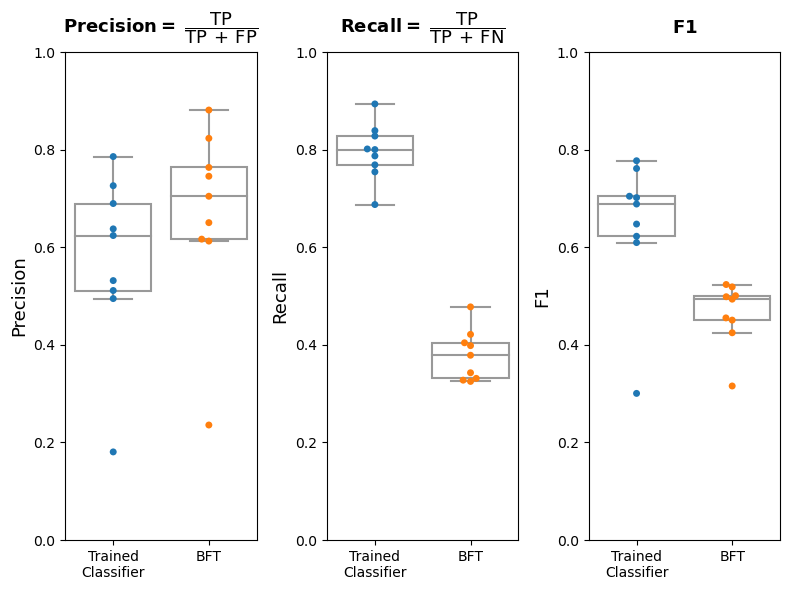

In [12]:
### GS VS BFT ###

fig,axes = plt.subplots(1,3,figsize=(8,6))
axes = axes.ravel()
results_df_long = pd.melt(results_df,id_vars=['fov'])

precision_order = [
    'model_precision',
    'bft_precision'
]

sns.boxplot(
    data=results_df_long.loc[results_df_long['variable'].isin(precision_order)],
    x='variable',
    y='value',
    order=precision_order,
    color='white',
    showfliers=False,
    ax=axes[0]
)

sns.swarmplot(
    data=results_df_long.loc[results_df_long['variable'].isin(precision_order)],
    x='variable',
    y='value',
    order=precision_order,
    ax=axes[0]
)
recall_order = [
    'model_recall',
    'bft_recall'
]

sns.boxplot(
    data=results_df_long.loc[results_df_long['variable'].isin(recall_order)],
    x='variable',
    y='value',
    order=recall_order,
    color='white',
    showfliers=False,
    ax=axes[1]
)

sns.swarmplot(
    data=results_df_long.loc[results_df_long['variable'].isin(recall_order)],
    x='variable',
    y='value',
    order=recall_order,
    ax=axes[1]
)

f1_order = [
    'model_f1',
    'bft_f1'
]

sns.boxplot(
    data=results_df_long.loc[results_df_long['variable'].isin(f1_order)],
    x='variable',
    y='value',
    order=f1_order,
    color='white',
    showfliers=False,
    ax=axes[2]
)

sns.swarmplot(
    data=results_df_long.loc[results_df_long['variable'].isin(f1_order)],
    x='variable',
    y='value',
    order=f1_order,
    ax=axes[2]
)

axes[0].set_title(r'$\mathbf{Precision = }$ $\dfrac{\mathrm{TP}}{\mathrm{TP} \,+\, \mathrm{FP}}$', fontsize=13, pad=14)
axes[1].set_title(r'$\mathbf{Recall = }$ $\dfrac{\mathrm{TP}} {\mathrm{TP} \,+\, \mathrm{FN}}$', fontsize=13, pad=14)
axes[2].set_title(r'$\mathbf{F1}$', fontsize=13, pad=14)

axes[0].set_ylabel('Precision', fontsize=13)
axes[1].set_ylabel('Recall', fontsize=13)
axes[2].set_ylabel('F1', fontsize=13)

for ax in axes:
    ax.set_xticks([0, 1])                                   # avoids the FixedFormatter warning
    ax.set_xticklabels(['Trained\nClassifier', 'BFT'])
    ax.set_xlabel('')                                       # kills the 'variable' label
    ax.set_ylim(0, 1)

fig.tight_layout()
fig.savefig(os.path.join(output_dir, 'testset_results_tissue_GS_BFT_only_final.svg'))

In [13]:
from scipy.stats import ttest_rel

# ================= shared functions =================
def p_to_stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

def compute_stats(df, methods, metrics, reference, test=ttest_rel):
    """Paired test of every method against the reference, for each metric."""
    df = df.sort_values('fov').reset_index(drop=True)
    rows = []
    for metric in metrics:
        for m in methods:
            if m == reference:
                continue
            stat, p = test(df[f'{m}_{metric}'], df[f'{reference}_{metric}'])
            rows.append({'test': metric, 'a': m, 'b': reference,
                         'type': f'{m} vs {reference}', 'stat': stat, 'p-value': p})
    stats_df = pd.DataFrame(rows)
    stats_df['stars'] = stats_df['p-value'].apply(p_to_stars)
    return stats_df

def add_significance(ax, x1, x2, y, h, text, fontsize=12, lw=0.8):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=lw, c='black')
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=fontsize)

def annotate_axis(ax, df, methods, metric, stats_df, show_ns=True,
                  gap=0.04, step=0.07, h=0.015, ymin_zero=False):
    vals = df[[f'{m}_{metric}' for m in methods]].to_numpy()
    lo, hi = vals.min(), vals.max()
    rng = hi - lo
    sub = stats_df[stats_df['test'] == metric]
    if not show_ns:
        sub = sub[sub['stars'] != 'ns']
    # list comprehension instead of df.apply: apply() breaks when sub is empty (all 'ns' + show_ns=False)
    sub = sub.assign(span=[abs(methods.index(a) - methods.index(b))
                           for a, b in zip(sub['a'], sub['b'])])
    y = hi + gap * rng
    for _, row in sub.sort_values('span').iterrows():
        x1, x2 = sorted([methods.index(row['a']), methods.index(row['b'])])
        add_significance(ax, x1, x2, y, h * rng, row['stars'])
        y += step * rng
    bottom = min(0, lo) if ymin_zero else None
    ax.set_ylim(bottom, y + 0.02 * rng)

def plot_benchmark(df, methods, metrics, labels, titles, stats_df,
                   colors=None, show_ns=True, ymin_zero=False,
                   figsize=None, tick_fontsize=12):
    df = df.sort_values('fov').reset_index(drop=True)
    long = pd.melt(df, id_vars=['fov'])
    figsize = figsize or (4 * len(metrics), 6)
    fig, axes = plt.subplots(1, len(metrics), figsize=figsize, squeeze=False)
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics):
        order = [f'{m}_{metric}' for m in methods]
        sub = long[long['variable'].isin(order)]
        sns.boxplot(data=sub, x='variable', y='value', order=order,
                    color='white', showfliers=False, ax=ax)
        if colors:
            palette = {f'{m}_{metric}': colors[m] for m in methods}
            sns.swarmplot(data=sub, x='variable', y='value', order=order,
                          hue='variable', hue_order=order, palette=palette, ax=ax)
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        else:
            sns.swarmplot(data=sub, x='variable', y='value', order=order, ax=ax)

        annotate_axis(ax, df, methods, metric, stats_df,
                      show_ns=show_ns, ymin_zero=ymin_zero)
        title_tex = titles[metric].replace(' ', r'\ ')
        ax.set_title(rf'$\mathbf{{{title_tex}}}$', fontsize=13, pad=14)
        ax.set_ylabel(titles[metric], fontsize=13)
        ax.set_xlabel('')
        ax.set_xticks(range(len(methods)), labels=[labels[m] for m in methods],
                      fontsize=tick_fontsize)

    fig.tight_layout()
    return fig, axes

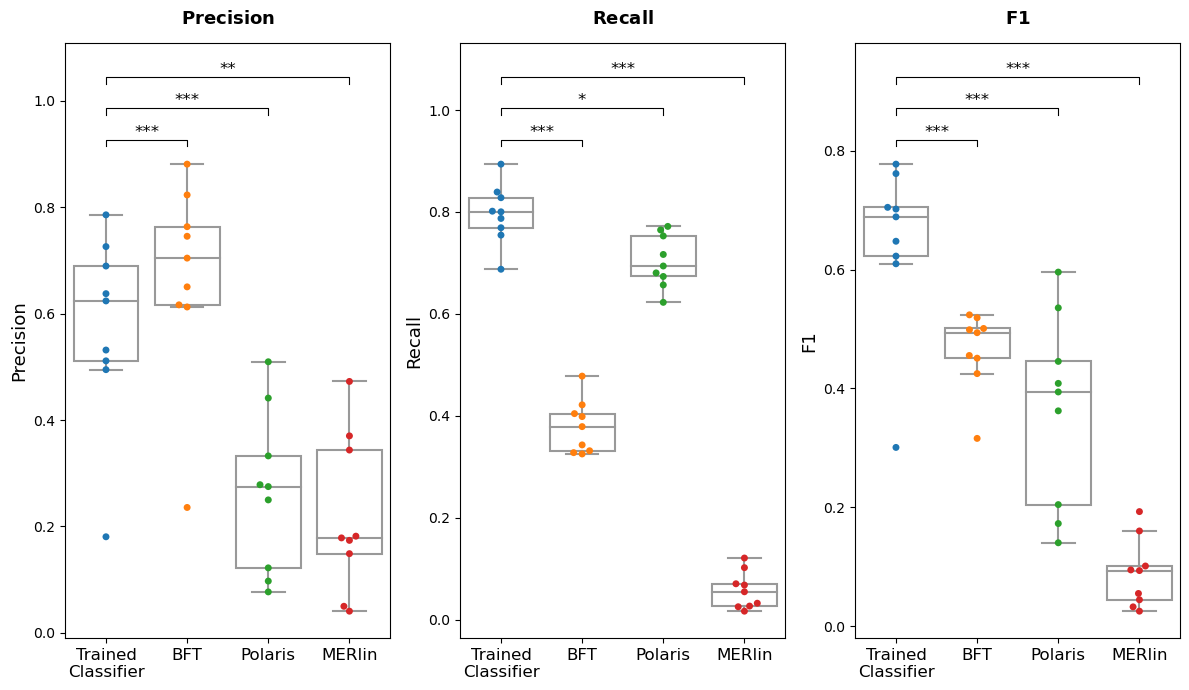

In [14]:
reference = 'model'
methods = ['model', 'bft', 'polaris', 'merlin']
labels  = {'model': 'Trained\nClassifier', 'bft': 'BFT',
           'polaris': 'Polaris', 'merlin': 'MERlin'}
titles  = {'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1', 'auroc': 'AUROC'}

stats_results_df = compute_stats(results_df, methods,
                                 ['precision', 'recall', 'f1', 'auroc'], reference)
fig, axes = plot_benchmark(results_df, methods, ['precision', 'recall', 'f1'],
                           labels, titles, stats_results_df, figsize=(12, 7))
fig.savefig(os.path.join(output_dir, 'testset_results_tissue_benchmark_final_p_edge_crop.svg'))

In [15]:
results_df.describe()

,fov,model_precision,model_recall,model_f1,model_auroc,bft_precision,bft_recall,bft_f1,bft_auroc,polaris_precision,polaris_recall,polaris_f1,polaris_auroc,merlin_precision,merlin_recall,merlin_f1,merlin_auroc
count,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000
mean,4.000000,0.575839,0.795677,0.646044,0.837700,0.670483,0.378688,0.464723,0.813356,0.264909,0.703660,0.361995,0.590020,0.217878,0.057443,0.088623,0.294688
std,2.738613,0.178426,0.057839,0.141483,0.027259,0.186704,0.052085,0.064961,0.033437,0.149966,0.051545,0.160019,0.041114,0.147102,0.036370,0.057507,0.045995
min,0.000000,0.180680,0.687596,0.300595,0.775575,0.235808,0.325153,0.315789,0.739489,0.077044,0.622642,0.140100,0.506906,0.040816,0.016667,0.025000,0.245026
25%,2.000000,0.511435,0.768994,0.622595,0.838680,0.616732,0.331404,0.450787,0.811718,0.122222,0.673397,0.204334,0.571492,0.148936,0.026667,0.044199,0.266004
50%,4.000000,0.624122,0.800275,0.688650,0.843971,0.704615,0.378788,0.493718,0.814544,0.275035,0.693950,0.393939,0.589396,0.178571,0.054726,0.093333,0.274555
75%,6.000000,0.689708,0.827957,0.704663,0.851712,0.763689,0.404301,0.500790,0.836495,0.332746,0.752874,0.445405,0.623119,0.343750,0.070423,0.101010,0.317824
max,8.000000,0.785939,0.893805,0.777374,0.864220,0.881266,0.477876,0.523715,0.854397,0.509683,0.771654,0.595679,0.637845,0.472727,0.120930,0.192593,0.390461


In [16]:
results_df

,fov,model_precision,model_recall,model_f1,model_auroc,bft_precision,bft_recall,bft_f1,bft_auroc,polaris_precision,polaris_recall,polaris_f1,polaris_auroc,merlin_precision,merlin_recall,merlin_f1,merlin_auroc
0,0,0.689708,0.687596,0.688650,0.838680,0.745645,0.327718,0.455319,0.812182,0.097398,0.752874,0.172482,0.566424,0.050000,0.016667,0.025000,0.313071
1,1,0.494902,0.839096,0.622595,0.817510,0.616732,0.421543,0.500790,0.791214,0.332746,0.673397,0.445405,0.571492,0.472727,0.120930,0.192593,0.245026
2,2,0.624122,0.801504,0.701777,0.845034,0.763689,0.398496,0.523715,0.819762,0.509683,0.716584,0.595679,0.636909,0.343750,0.054726,0.094421,0.250781
3,3,0.726250,0.800275,0.761468,0.864220,0.823353,0.378788,0.518868,0.840402,0.441478,0.680380,0.535492,0.637845,0.181818,0.032258,0.054795,0.274555
4,4,0.785939,0.768994,0.777374,0.863825,0.881266,0.342916,0.493718,0.854397,0.278571,0.764706,0.408377,0.623119,0.173913,0.025316,0.044199,0.322170
5,5,0.637749,0.787265,0.704663,0.843971,0.704615,0.331404,0.450787,0.811718,0.275035,0.693950,0.393939,0.589396,0.370370,0.102041,0.160000,0.272300
6,6,0.511435,0.754601,0.609665,0.851712,0.612717,0.325153,0.424850,0.836495,0.250000,0.656757,0.362146,0.580940,0.178571,0.070423,0.101010,0.317824
7,7,0.531768,0.827957,0.647603,0.838773,0.650519,0.404301,0.498674,0.814544,0.077044,0.771654,0.140100,0.597148,0.040816,0.026667,0.032258,0.390461
8,8,0.180680,0.893805,0.300595,0.775575,0.235808,0.477876,0.315789,0.739489,0.122222,0.622642,0.204334,0.506906,0.148936,0.067961,0.093333,0.266004


In [ ]:
stats_results_df

,test,a,b,type,stat,p-value,stars
0,precision,bft,model,bft vs model,9.451069,1.291711e-05,***
1,precision,polaris,model,polaris vs model,-5.089361,9.421558e-04,***
2,precision,merlin,model,merlin vs model,-4.629765,1.688566e-03,**
3,recall,bft,model,bft vs model,-48.729770,3.480203e-11,***
4,recall,polaris,model,polaris vs model,-2.907820,1.965467e-02,*
5,recall,merlin,model,merlin vs model,-41.032300,1.370249e-10,***
6,f1,bft,model,bft vs model,-6.014866,3.180841e-04,***
7,f1,polaris,model,polaris vs model,-5.460969,6.008403e-04,***
8,f1,merlin,model,merlin vs model,-10.280210,6.903136e-06,***
9,auroc,bft,model,bft vs model,-9.095387,1.714800e-05,***


Using BFT as the 'reference' for pairwise comparison


In [ ]:
compute_stats(results_df, methods,
              ['precision', 'recall', 'f1', 'auroc'], 'bft')

,test,a,b,type,stat,p-value,stars
0,precision,model,bft,model vs bft,-9.451069,1.291711e-05,***
1,precision,polaris,bft,polaris vs bft,-6.856453,1.301350e-04,***
2,precision,merlin,bft,merlin vs bft,-5.865193,3.762478e-04,***
3,recall,model,bft,model vs bft,48.729770,3.480203e-11,***
4,recall,polaris,bft,polaris vs bft,11.157660,3.725715e-06,***
5,recall,merlin,bft,merlin vs bft,-17.037206,1.430587e-07,***
6,f1,model,bft,model vs bft,6.014866,3.180841e-04,***
7,f1,polaris,bft,polaris vs bft,-2.258320,5.386336e-02,ns
8,f1,merlin,bft,merlin vs bft,-12.490254,1.579170e-06,***
9,auroc,model,bft,model vs bft,9.095387,1.714800e-05,***


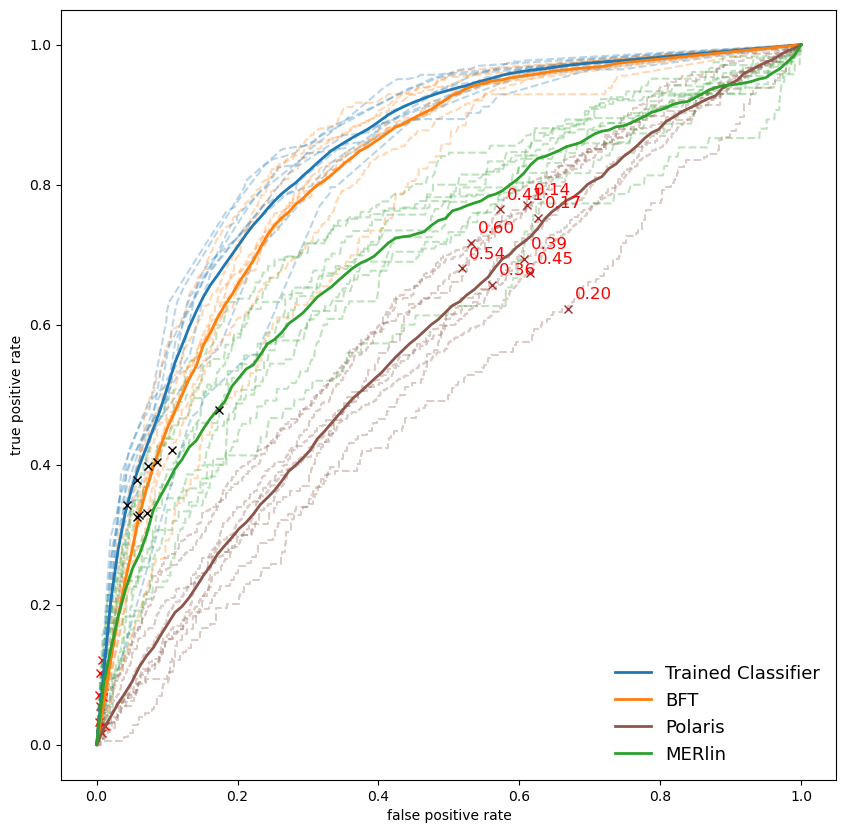

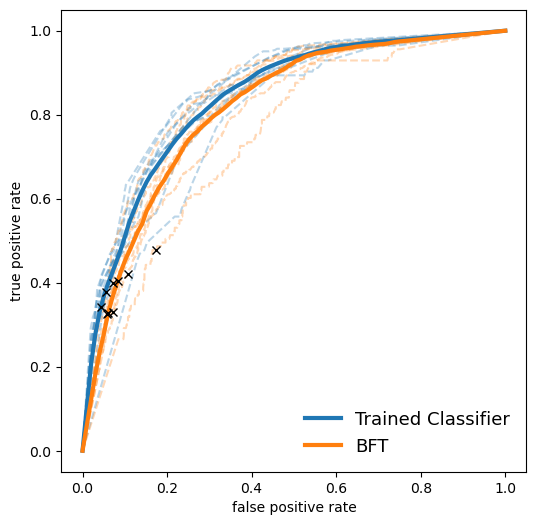

In [19]:
# --- storage ---
tprs_model, fprs_model, aucs_model = [], [], []
tprs_bft,   fprs_bft,   aucs_bft   = [], [], []
tprs_polaris, fprs_polaris, aucs_polaris = [], [], []
tprs_merlin,  aucs_merlin = [], []
mean_fpr = np.linspace(0, 1, 100)

# --- two figures: fig1 = all methods, fig2 = GS vs BFT only ---
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 10))
fig2, ax2 = plt.subplots(1, 1, figsize=(6, 6))

for j, test_fov in enumerate(testing_fovs):
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(
            fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(
        fov_subset_transformed[features_to_use])[:, 1]

    polaris_sub = polaris_gs_data.loc[polaris_gs_data['fov'] == test_fov].copy()
    polaris_sub['pred'] = (polaris_sub['probability'] >= 0.95).astype(int)

    merlin_sub = merlin_gs_data.loc[merlin_gs_data['fov'] == test_fov].copy()
    merlin_sub['pred'] = merlin_sub['pass_threshold'].astype(int)

    # --- restrict to GS genes once ---
    m = Y_fov_subset['gene'].isin(GS_gene_list)
    p = polaris_sub['gene'].isin(GS_gene_list)
    r = merlin_sub['gene'].isin(GS_gene_list)

    # --- ROC curves (no stray figures) ---
    fpr_model, tpr_model, _ = roc_curve(Y_fov_subset.loc[m, 'Label'],
                                        Y_fov_subset.loc[m, 'pred_score'])
    auc_model = roc_auc_score(Y_fov_subset.loc[m, 'Label'],
                              Y_fov_subset.loc[m, 'pred_score'])

    fpr_bft, tpr_bft, _ = roc_curve(Y_fov_subset.loc[m, 'Label'],
                                    1 - Y_fov_subset.loc[m, 'bfs'])
    auc_bft = roc_auc_score(Y_fov_subset.loc[m, 'Label'],
                            1 - Y_fov_subset.loc[m, 'bfs'])

    fpr_pol, tpr_pol, _ = roc_curve(polaris_sub.loc[p, 'Label'],
                                    polaris_sub.loc[p, 'probability'])
    auc_pol = roc_auc_score(polaris_sub.loc[p, 'Label'],
                            polaris_sub.loc[p, 'probability'])

    fpr_mer, tpr_mer, _ = roc_curve(merlin_sub.loc[r, 'Label'],
                                    1 - merlin_sub.loc[r, 'merlin_bfs'])
    auc_mer = roc_auc_score(merlin_sub.loc[r, 'Label'],
                            1 - merlin_sub.loc[r, 'merlin_bfs'])

    # --- interpolate + store ---
    for fpr_, tpr_, auc_, tl, fl, al in [
        (fpr_model, tpr_model, auc_model, tprs_model, fprs_model, aucs_model),
        (fpr_bft,   tpr_bft,   auc_bft,   tprs_bft,   fprs_bft,   aucs_bft),
        (fpr_pol,   tpr_pol,   auc_pol,   tprs_polaris, fprs_polaris, aucs_polaris),
    ]:
        it = np.interp(mean_fpr, fpr_, tpr_); it[0] = 0
        ifp = np.interp(mean_fpr, tpr_, fpr_); ifp[0] = 0
        tl.append(it); fl.append(ifp); al.append(auc_)

    it_mer = np.interp(mean_fpr, fpr_mer, tpr_mer); it_mer[0] = 0
    tprs_merlin.append(it_mer); aucs_merlin.append(auc_mer)

    # --- per-FOV faint curves ---
    # fig1: all four
    ax1.plot(fpr_model, tpr_model, ls='dashed', alpha=0.3, color='tab:blue')
    ax1.plot(fpr_bft,   tpr_bft,   ls='dashed', alpha=0.3, color='tab:orange')
    ax1.plot(fpr_pol,   tpr_pol,   ls='dashed', alpha=0.3, color='tab:brown')
    ax1.plot(fpr_mer,   tpr_mer,   ls='dashed', alpha=0.3, color='tab:green')
    # fig2: GS + BFT only
    ax2.plot(fpr_model, tpr_model, ls='dashed', alpha=0.3, color='tab:blue')
    ax2.plot(fpr_bft,   tpr_bft,   ls='dashed', alpha=0.3, color='tab:orange')

    # --- BFT operating point (goes on BOTH figures) ---
    TP = ((Y_fov_subset['Label'] == 1) & (Y_fov_subset['bft_result'] == 1) & m).sum()
    FP = ((Y_fov_subset['Label'] == 0) & (Y_fov_subset['bft_result'] == 1) & m).sum()
    FN = ((Y_fov_subset['Label'] == 1) & (Y_fov_subset['bft_result'] == 0) & m).sum()
    TN = ((Y_fov_subset['Label'] == 0) & (Y_fov_subset['bft_result'] == 0) & m).sum()
    misid_fpr = FP / (FP + TN)
    misid_tpr = TP / (TP + FN)
    ax1.plot(misid_fpr, misid_tpr, 'x', color='black', zorder=10)
    ax2.plot(misid_fpr, misid_tpr, 'x', color='black', zorder=10)

    # --- Polaris @0.95 operating point (fig1 only) ---
    TP_p = ((polaris_sub['Label'] == 1) & (polaris_sub['pred'] == 1) & p).sum()
    FP_p = ((polaris_sub['Label'] == 0) & (polaris_sub['pred'] == 1) & p).sum()
    FN_p = ((polaris_sub['Label'] == 1) & (polaris_sub['pred'] == 0) & p).sum()
    TN_p = ((polaris_sub['Label'] == 0) & (polaris_sub['pred'] == 0) & p).sum()
    ax1.plot(FP_p / (FP_p + TN_p), TP_p / (TP_p + FN_p), 'x', color='brown')
    pol_f1 = f1_score(polaris_sub.loc[p, 'Label'], polaris_sub.loc[p, 'pred'])
    ax1.text(FP_p / (FP_p + TN_p) + 0.01, TP_p / (TP_p + FN_p) + 0.01,
             f'{pol_f1:.2f}', color='red', fontsize=12, ha='left', va='bottom')

    # --- MERlin operating point (fig1 only) ---
    TP_m = ((merlin_sub['Label'] == 1) & (merlin_sub['pred'] == 1) & r).sum()
    FP_m = ((merlin_sub['Label'] == 0) & (merlin_sub['pred'] == 1) & r).sum()
    FN_m = ((merlin_sub['Label'] == 1) & (merlin_sub['pred'] == 0) & r).sum()
    TN_m = ((merlin_sub['Label'] == 0) & (merlin_sub['pred'] == 0) & r).sum()
    ax1.plot(FP_m / (FP_m + TN_m), TP_m / (TP_m + FN_m), 'x', color='red')

# --- mean curves ---
mean_tpr_model   = np.mean(tprs_model,   axis=0); mean_tpr_model[-1]   = 1
mean_tpr_bft     = np.mean(tprs_bft,     axis=0); mean_tpr_bft[-1]     = 1
mean_tpr_polaris = np.mean(tprs_polaris, axis=0); mean_tpr_polaris[-1] = 1
mean_tpr_merlin  = np.mean(tprs_merlin,  axis=0); mean_tpr_merlin[-1]  = 1

ax1.plot(mean_fpr, mean_tpr_model,   color='tab:blue',   lw=2, label='Trained Classifier')
ax1.plot(mean_fpr, mean_tpr_bft,     color='tab:orange', lw=2, label='BFT')
ax1.plot(mean_fpr, mean_tpr_polaris, color='tab:brown',  lw=2, label='Polaris')
ax1.plot(mean_fpr, mean_tpr_merlin,  color='tab:green',  lw=2, label='MERlin')

ax2.plot(mean_fpr, mean_tpr_model, color='tab:blue',   lw=3, label='Trained Classifier')
ax2.plot(mean_fpr, mean_tpr_bft,   color='tab:orange', lw=3, label='BFT')

for ax in (ax1, ax2):
    ax.legend(loc='lower right', fontsize=13, markerscale=1.5, frameon=False)
    ax.set_xlabel('false positive rate')
    ax.set_ylabel('true positive rate')

fig1.savefig(os.path.join(output_dir, 'ROC_withmisid_LM39_tissue_benchmark.svg'))
fig2.savefig(os.path.join(output_dir, 'ROC_liver_withmisid_GS_BFT_only.svg'))

In [20]:
from sklearn.metrics import auc

auc_mean_model   = auc(mean_fpr, mean_tpr_model)
auc_mean_bft     = auc(mean_fpr, mean_tpr_bft)
auc_mean_polaris = auc(mean_fpr, mean_tpr_polaris)
auc_mean_merlin  = auc(mean_fpr, mean_tpr_merlin)

print(f'AUC mean for Trained Classifier: {auc_mean_model:.3f}')
print(f'AUC mean for BFT: {auc_mean_bft:.3f}')
print(f'AUC mean for Polaris: {auc_mean_polaris:.3f}')
print(f'AUC mean for MERlin: {auc_mean_merlin:.3f}')

AUC mean for Trained Classifier: 0.838
AUC mean for BFT: 0.813
AUC mean for Polaris: 0.590
AUC mean for MERlin: 0.705


In [21]:
# merfish by fov
model_fpkm_result = []
model_counts_result = []
model_misid_result = []

bft_fpkm_result = []
bft_counts_result = []
bft_misid_result = []

all_model_callouts = []
all_bft_callouts = []

merfish_data['bft_result'] = 0
merfish_data.loc[merfish_data['bfs'] <= bft, 'bft_result'] = 1
for merfish_fov in range(nfovs):
    merfish_subset = merfish_data[features_to_use + ['bfs', 'bft_result', 'gene']].loc[merfish_data['fov'] == merfish_fov]
    merfish_subset_transformed = cm.transform(merfish_subset[features_to_use])
    for col in merfish_subset_transformed.columns:
        merfish_subset_transformed[col] = merfish_subset_transformed[col].fillna(merfish_subset_transformed[col].max())
    merfish_subset_transformed['pred'] = RF.predict(merfish_subset_transformed[features_to_use])
    model_callouts = list(merfish_subset['gene'].loc[merfish_subset_transformed['pred']==1])
    model_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, model_callouts)
    model_fpkm_val, _ = calcLogCorrelation(np.array(model_counts_arr), np.array(fpkm_list))
    model_mis_id_rate = calc_misid(model_counts_arr, model_callouts)
    
    bft_callouts = list(merfish_subset['gene'].loc[merfish_subset['bft_result']==1])
    bft_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, bft_callouts)
    bft_fpkm_val, _ = calcLogCorrelation(np.array(bft_counts_arr), np.array(fpkm_list))
    bft_mis_id_rate = calc_misid(bft_counts_arr, bft_callouts)
    
    model_fpkm_result.append(model_fpkm_val)
    model_counts_result.append(np.sum(model_counts_arr))
    model_misid_result.append(model_mis_id_rate)
    
    bft_fpkm_result.append(bft_fpkm_val)
    bft_counts_result.append(np.sum(bft_counts_arr))
    bft_misid_result.append(bft_mis_id_rate)

    all_model_callouts.extend(model_callouts)
    all_bft_callouts.extend(bft_callouts)

In [26]:
# load process data 
polaris_fpkm_result = []
polaris_counts_result = []
polaris_fov = []

all_polaris_callouts = []

folder = Path(polaris_main)
for file in folder.glob('*Polaris_prediction.csv'):
    fov = int(file.name.split('_')[0])
    polaris_fov.append(fov)
    df_polaris_sub = pd.read_csv(file)

    ### keep only probability >= 0.95
    df_polaris_sub = df_polaris_sub[df_polaris_sub['probability'] >= 0.95]
    polaris_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_polaris_sub['predicted_name'].tolist())
    polaris_fpkm_val, _ = calcLogCorrelation(np.array(polaris_counts_arr), np.array(fpkm_list))
    polaris_fpkm_result.append(polaris_fpkm_val)
    polaris_counts_result.append(np.sum(polaris_counts_arr))
    all_polaris_callouts.extend(df_polaris_sub['predicted_name'].tolist())
### format polaris output
# glob() does not return files in numeric FOV order (e.g. 0, 1, 10, 11, ...), so sort by fov
# before the columns are placed next to the other methods -- otherwise the paired t-tests pair the wrong FOVs
polaris_df_result = pd.DataFrame({'fov':polaris_fov, 'polaris_fpkm': polaris_fpkm_result,
                                  'polaris_count': polaris_counts_result}).sort_values('fov').reset_index(drop=True)
assert polaris_df_result['fov'].tolist() == list(range(nfovs)), 'Polaris FOVs missing or duplicated'

In [27]:
# this is matching starfish global normalization (for scale factor computation) to 99.9 percentile & 57 median in GS 
starfish_fpkm_result = []
starfish_counts_result = []
df_starfish = pd.read_csv(os.path.join(main_dir, 'Data/benchmarking/starfish/liver/starfish_result/lm39_tissue_starfish_multifov.csv'))
for sub_fov in range(nfovs):
    df_starfish_sub = df_starfish[df_starfish['fov'] == f'fov_{str(sub_fov).zfill(3)}']
    starfish_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_starfish_sub['target'].tolist())
    starfish_fpkm_val, _ = calcLogCorrelation(np.array(starfish_counts_arr), np.array(fpkm_list))
    starfish_fpkm_result.append(starfish_fpkm_val)
    starfish_counts_result.append(np.sum(starfish_counts_arr))

In [28]:
### process MERlin
merlin_fpkm_result = []
merlin_counts_result= []
merlin_fov = []

all_merlin_callouts = []

for fov in range(nfovs):
    merlin_fov.append(fov)
    file = os.path.join(main_dir, f'Data/benchmarking/merlin/Final_used_data/analysis_20260521_144432/Data_60uM/AdaptiveFilterBarcodes/Adaptivefilter_{fov}.csv')
    df_merlin_sub = pd.read_csv(file)
    df_merlin_sub['gene_name'] = df_merlin_sub['barcode_id'].map(df_fpkm['genes'].to_dict())
    df_merlin_sub = df_merlin_sub[df_merlin_sub['passes_threshold']==True] # only select data that pass Adaptive Filtering in MERlin
    merlin_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_merlin_sub['gene_name'].tolist())
    merlin_fpkm_val, _ = calcLogCorrelation(np.array(merlin_counts_arr), np.array(fpkm_list))
    merlin_fpkm_result.append(merlin_fpkm_val)
    merlin_counts_result.append(np.sum(merlin_counts_arr))
    all_merlin_callouts.extend(df_merlin_sub['gene_name'].tolist())

In [29]:
merfish_results_df = pd.DataFrame({'fov':[i for i in range(nfovs)], 
                                   'model_fpkm': model_fpkm_result, 'model_counts':model_counts_result, 'model_misid': model_misid_result,
                                   'bft_fpkm': bft_fpkm_result, 'bft_counts': bft_counts_result, 'bft_misid': bft_misid_result,
                                   'starfish_fpkm': starfish_fpkm_result, 'starfish_counts': starfish_counts_result,
                                   'polaris_fpkm': polaris_df_result['polaris_fpkm'].tolist(), 'polaris_counts': polaris_df_result['polaris_count'].tolist(),
                                   'merlin_fpkm': merlin_fpkm_result, 'merlin_counts': merlin_counts_result
                                   })
merfish_results_df.to_csv(os.path.join(output_dir, 'full_benchmarking_merfish_results_tissue.csv'))
merfish_results_df_long = pd.melt(merfish_results_df,id_vars=['fov'])

<user_home>\AppData\Local\miniforge3\envs\GS_JZ_new\lib\site-packages\seaborn\categorical.py:1296: UserWarning: 12.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


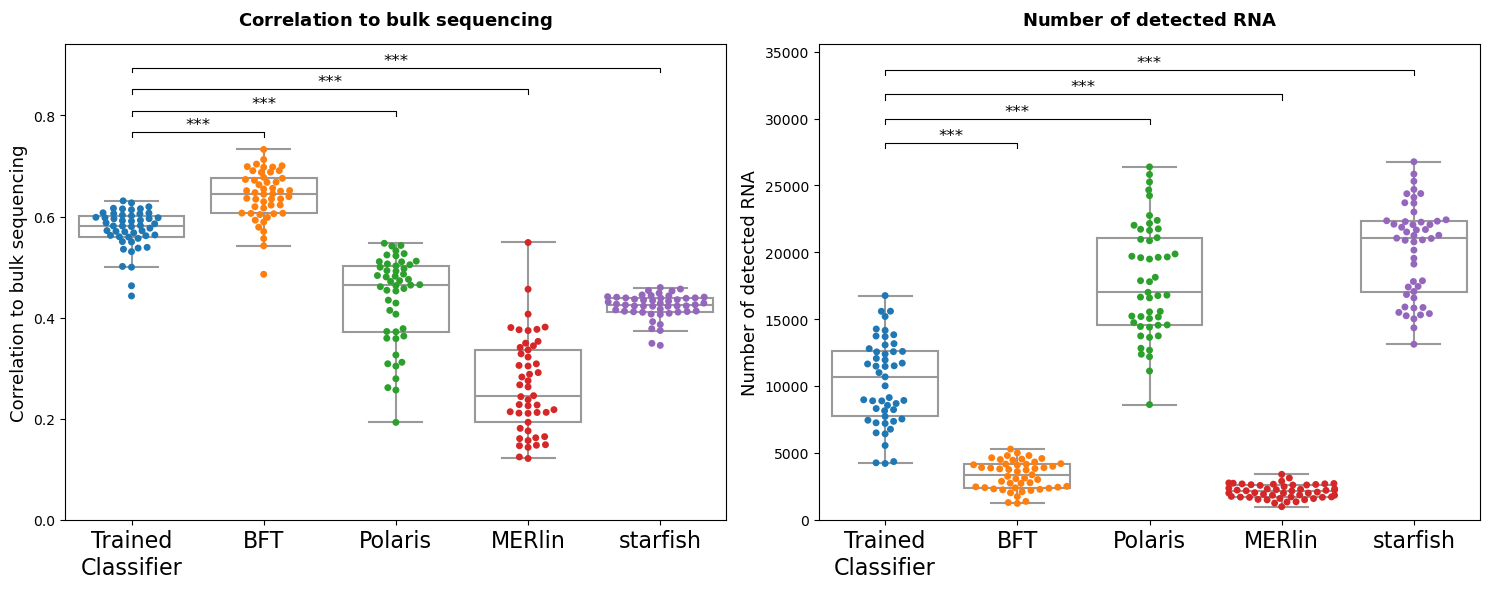

In [31]:
methods_all = ['model', 'bft', 'polaris', 'merlin', 'starfish']
labels_all  = {**labels, 'starfish': 'starfish'}
colors      = {'model': '#1f77b4', 'bft': '#ff7f0e', 'polaris': '#2ca02c',
               'merlin': '#d62728', 'starfish': '#9467bd'}
titles_cnt  = {'fpkm': 'Correlation to bulk sequencing', 'counts': 'Number of detected RNA'}

count_results_df = compute_stats(merfish_results_df, methods_all,
                                 ['fpkm', 'counts'], reference)
fig, axes = plot_benchmark(merfish_results_df, methods_all, ['fpkm', 'counts'],
                           labels_all, titles_cnt, count_results_df,
                           colors=colors, show_ns=False, ymin_zero=True,
                           figsize=(15, 6), tick_fontsize=16)
fig.savefig(os.path.join(output_dir, 'benchmark_merfish_results_tissue_withwhole_ref_model_p_edge_crop.svg'))


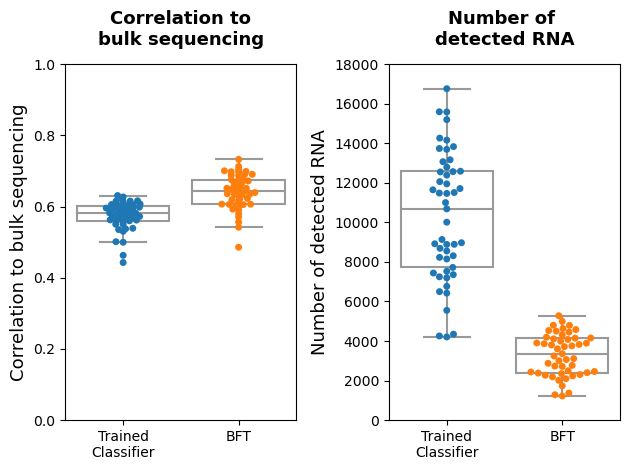

In [32]:
# FPKM, counts on all genes GS VS BFT only
fig,axes = plt.subplots(1,2)
axes = axes.ravel()
merfish_results_df_long = pd.melt(merfish_results_df,id_vars=['fov'])

sns.boxplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_fpkm','bft_fpkm'])], x = 'variable',y='value', color='white',showfliers=False,ax=axes[0])
sns.swarmplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_fpkm','bft_fpkm'])], x = 'variable',y='value',ax=axes[0])
axes[0].plot([0,1], [model_fpkm_val,bft_fpkm_val],'^',color='black',markersize=7)

sns.boxplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_counts','bft_counts'])], x = 'variable',y='value', color='white',showfliers=False,ax=axes[1])
sns.swarmplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_counts','bft_counts'])], x = 'variable',y='value',ax=axes[1])
#axes[1].plot([0,1], [np.sum(model_counts_arr)/nfovs,np.sum(bft_counts_arr)/nfovs],'^',color='black',markersize=7)

axes[0].set_ylim(0,1)
axes[1].set_ylim(0,18000) # liver

axes[0].set_title('fpkm')
axes[1].set_title('counts')

for ax in axes:
    ax.set_xticks([0, 1])                                   # avoids the FixedFormatter warning
    ax.set_xticklabels(['Trained\nClassifier', 'BFT'])
    ax.set_xlabel('')                                       # kills the 'variable' label

axes[0].set_title('Correlation to\nbulk sequencing', fontsize=13, fontweight='bold', pad=14)
axes[1].set_title('Number of \ndetected RNA', fontsize=13, fontweight='bold', pad=14)
axes[0].set_ylabel('Correlation to bulk sequencing', fontsize=13)
axes[1].set_ylabel('Number of detected RNA', fontsize=13)

fig.tight_layout()
fig.savefig(os.path.join(output_dir, 'merfish_results_liver_withwhole_GS_BFT_only.svg'))

In [33]:
count_results_df

,test,a,b,type,stat,p-value,stars
0,fpkm,bft,model,bft vs model,16.271871,3.613564e-21,***
1,fpkm,polaris,model,polaris vs model,-10.554039,4.207941e-14,***
2,fpkm,merlin,model,merlin vs model,-24.663641,6.520425e-29,***
3,fpkm,starfish,model,starfish vs model,-46.349498,1.632924e-41,***
4,counts,bft,model,bft vs model,-22.297738,5.634988e-27,***
5,counts,polaris,model,polaris vs model,17.248869,3.284526e-22,***
6,counts,merlin,model,merlin vs model,-20.422782,2.574055e-25,***
7,counts,starfish,model,starfish vs model,33.635704,4.988661e-35,***


In [34]:
merfish_results_df.describe()

,fov,model_fpkm,model_counts,model_misid,bft_fpkm,bft_counts,bft_misid,starfish_fpkm,starfish_counts,polaris_fpkm,polaris_counts,merlin_fpkm,merlin_counts
count,49.00000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000
mean,24.00000,0.574868,10301.428571,0.400815,0.641474,3305.183673,0.081212,0.422516,20191.224490,0.437979,17851.591837,0.264594,2115.571429
std,14.28869,0.039086,3214.753930,0.063375,0.048378,1061.819697,0.029311,0.024505,3460.353175,0.087491,4207.055443,0.094569,524.068777
min,0.00000,0.442801,4205.000000,0.250427,0.485696,1218.000000,0.027434,0.345014,13122.000000,0.192588,8610.000000,0.121181,973.000000
25%,12.00000,0.559983,7723.000000,0.366004,0.606845,2399.000000,0.067028,0.411991,17068.000000,0.372460,14569.000000,0.192839,1701.000000
50%,24.00000,0.581378,10685.000000,0.402941,0.645051,3359.000000,0.075464,0.425398,21060.000000,0.465088,17008.000000,0.245444,2151.000000
75%,36.00000,0.601409,12588.000000,0.436584,0.675639,4144.000000,0.094907,0.438989,22329.000000,0.502451,21095.000000,0.335989,2592.000000
max,48.00000,0.631065,16763.000000,0.556062,0.732717,5279.000000,0.157055,0.459509,26777.000000,0.547063,26392.000000,0.548625,3392.000000


<user_home>\AppData\Local\miniforge3\envs\GS_JZ_new\lib\site-packages\seaborn\categorical.py:1296: UserWarning: 8.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


,test,a,b,type,stat,p-value,stars
0,fpkm,model,bft,model vs bft,-16.271871,3.613564e-21,***
1,fpkm,polaris,bft,polaris vs bft,-15.522566,2.436879e-20,***
2,fpkm,merlin,bft,merlin vs bft,-30.383131,5.305145e-33,***
3,fpkm,starfish,bft,starfish vs bft,-41.219264,3.976094e-39,***
4,counts,model,bft,model vs bft,22.297738,5.634988e-27,***
5,counts,polaris,bft,polaris vs bft,27.730807,3.374078e-31,***
6,counts,merlin,bft,merlin vs bft,-11.290884,4.105071e-15,***
7,counts,starfish,bft,starfish vs bft,45.072994,6.057930e-41,***


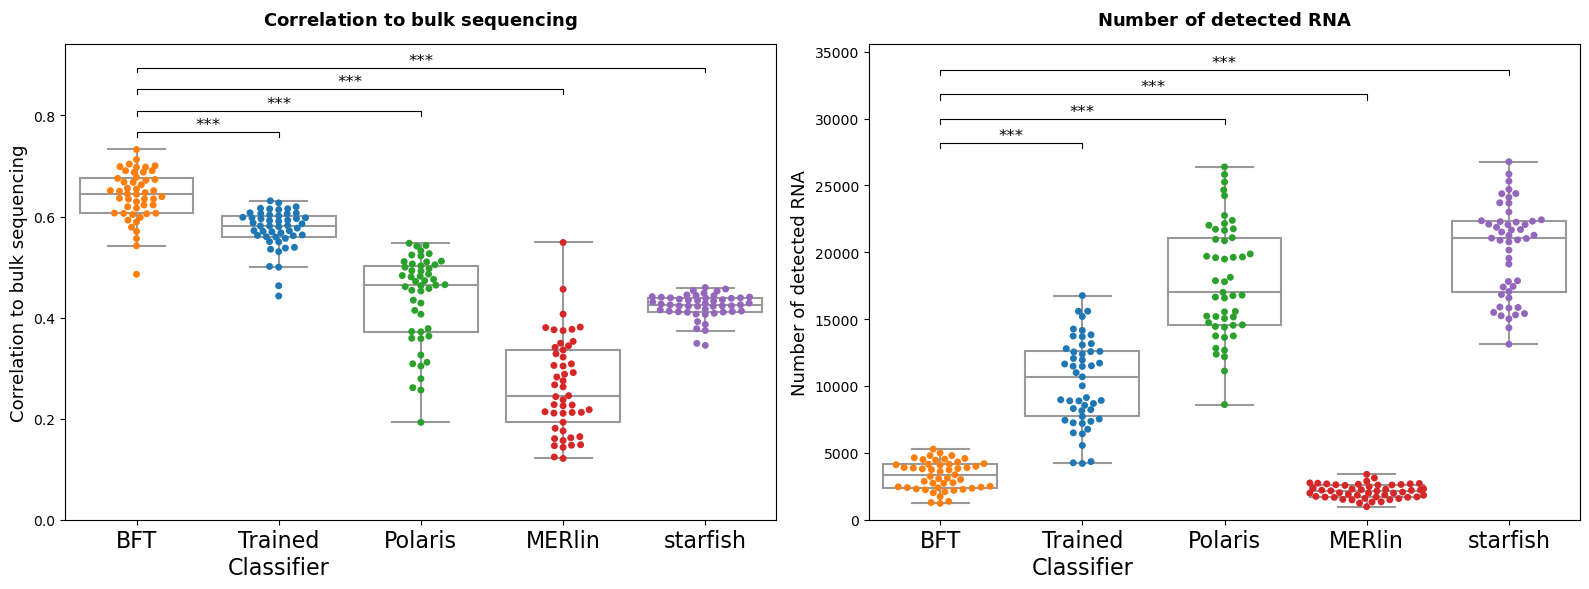

In [35]:
methods_all = ['bft', 'model', 'polaris', 'merlin', 'starfish']   # BFT at x=0, classifier at x=1

reference_bft = 'bft'
count_results_df = compute_stats(merfish_results_df, methods_all,
                                 ['fpkm', 'counts'], reference_bft)
fig, axes = plot_benchmark(merfish_results_df, methods_all, ['fpkm', 'counts'],
                           labels_all, titles_cnt, count_results_df,
                           colors=colors, show_ns=False, ymin_zero=True,
                           figsize=(16, 6), tick_fontsize=16)
fig.savefig(os.path.join(output_dir, 'benchmark_merfish_results_tissue_withwhole_ref_BFT_p_cropedge.svg'))
count_results_df


In [37]:
merfish_results_df.sum()

fov                  1176.000000
model_fpkm             28.168526
model_counts       504770.000000
model_misid            19.639927
bft_fpkm               31.432222
bft_counts         161954.000000
bft_misid               3.979372
starfish_fpkm          20.703290
starfish_counts    989370.000000
polaris_fpkm           21.460983
polaris_counts     874728.000000
merlin_fpkm            12.965116
merlin_counts      103663.000000
dtype: float64

## Compute the FPKM correlation for each method over ALL FOVs 
each point is 1 gene of interest

In [38]:
from typing import Mapping, Optional, Tuple
from matplotlib.ticker import LogLocator, NullFormatter

def logAxisLimits(values,
                  pad: float = 0.06,
                  snap: bool = True,
                  min_decades: float = 1.0,
                  ):
    """
    Decade-snapped (low, high) limits for a log axis, from the positive finite
    values only. Zeros and NaNs are ignored -- they cannot be shown on a log
    axis anyway, and calcLogCorrelation already masks them out.
    """
    v = np.asarray(values, dtype=float).ravel()
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        return (1e-1, 1e1)
 
    low, high = np.log10(v.min()), np.log10(v.max())
    span = max(high - low, min_decades)
    low -= pad * span
    high += pad * span
    if snap:
        low, high = np.floor(low), np.ceil(high)
    return (float(10 ** low), float(10 ** high))

def plotFPKMCorrelation(datasets: Mapping[str, pd.DataFrame],
                        fpkm_column: str = "FPKM",
                        count_column: str = "spot_count",
                        colours: Optional[Mapping[str, str]] = None,
                        labels: Optional[Mapping[str, str]] = None,
                        title: str = "AML-12 cell line sample",
                        subtitle: str = "Correlation of spot counts with RNAseq FPKM value",
                        xlabel: str = "FPKM value",
                        ylabel: str = "RNA spot counts",
                        xlim: Optional[Tuple[float, float]] = None,
                        ylim: Optional[Tuple[float, float]] = None,
                        point_size: float = 16,
                        alpha: float = 0.85,
                        figsize: Tuple[float, float] = (5.2, 4.6),
                        ax: Optional[plt.Axes] = None,
                        ):
    """
    datasets: {"Guidestar": merged_df, "BFT": merged_df} where each merged_df
    has an FPKM column and a spot-count column.
 
    returns (fig, ax, {label: (correlation, p_value)})
    """
    colours = dict(DEFAULT_COLOURS) if colours is None else dict(colours)
    labels = {} if labels is None else dict(labels)
 
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=150)
    else:
        fig = ax.figure
 
    correlations = {}

    if xlim is None:
        xlim = logAxisLimits(np.concatenate(
            [np.asarray(d[fpkm_column], dtype=float) for d in datasets.values()]))
    if ylim is None:
        ylim = logAxisLimits(np.concatenate(
            [np.asarray(d[count_column], dtype=float) for d in datasets.values()]))
 
    for i, (key, df) in enumerate(datasets.items()):
        label = labels.get(key, key)
        fpkm_values = np.asarray(df[fpkm_column], dtype=float)
        spot_counts = np.asarray(df[count_column], dtype=float)
        colour = colours.get(key, colours.get(label, f"C{i}"))
 
        ax.scatter(fpkm_values, spot_counts,
                   s=point_size, color=colour, alpha=alpha,
                   linewidths=0, label=label, zorder=3)
 
        correlation, p_value = calcLogCorrelation(fpkm_values, spot_counts)
        correlations[key] = (correlation, p_value)
 
        ax.text(0.035, 0.965 - 0.06 * i, f"{label} = {correlation:.3f}",
                transform=ax.transAxes, ha="left", va="top",
                color=colour, fontsize=10, fontweight="bold", zorder=4)
 
    # --- log-log axes ---
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(LogLocator(base=10.0))
    ax.yaxis.set_major_locator(LogLocator(base=10.0))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1))
        axis.set_minor_formatter(NullFormatter())
 
    # --- styling: grey panel, white gridlines, no spines ---
    ax.set_facecolor("#EAEAF2")
    ax.grid(True, which="major", color="white", linewidth=1.0)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(which="major", length=3, width=0.8, colors="#333333", labelsize=9)
    ax.tick_params(which="minor", length=0)
 
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=24)
    ax.text(0.5, 1.025, subtitle, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=9)
 
    fig.tight_layout()
    return fig, ax, correlations

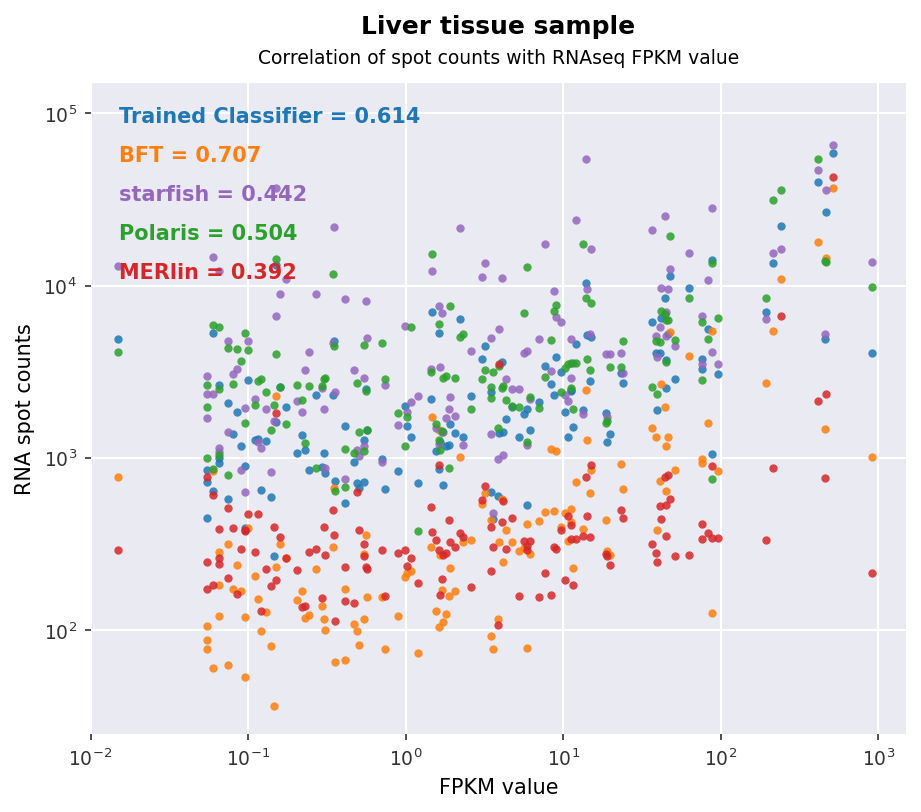

In [39]:
pooled = df_fpkm[["genes", "FPKM"]].copy().set_index("genes")   # adjust column names
pooled["model_counts"] = pd.Series(Counter(all_model_callouts)).reindex(pooled.index).fillna(0)
pooled["bft_counts"] = pd.Series(Counter(all_bft_callouts)).reindex(pooled.index).fillna(0)
all_starfish_callouts = df_starfish['target'].tolist()
pooled["starfish_counts"] = pd.Series(Counter(all_starfish_callouts)).reindex(pooled.index).fillna(0)
pooled["polaris_counts"] = pd.Series(Counter(all_polaris_callouts)).reindex(pooled.index).fillna(0)
pooled['merlin_counts'] = pd.Series(Counter(all_merlin_callouts)).reindex(pooled.index).fillna(0)

datasets = {
    "model": pooled.rename(columns={"model_counts": "spot_count"}),
    "bft": pooled.rename(columns={"bft_counts": "spot_count"}),
    "starfish": pooled.rename(columns={"starfish_counts": "spot_count"}),
    'polaris': pooled.rename(columns={"polaris_counts": "spot_count"}),
    'merlin': pooled.rename(columns={"merlin_counts": "spot_count"})
}
 
labels = {"model": "Trained Classifier", "bft": "BFT", "starfish": "starfish",
          "polaris": "Polaris", "merlin": "MERlin"}

fig, ax, correlations = plotFPKMCorrelation(datasets, colours=colors, labels=labels, title='Liver tissue sample', 
                                            figsize= (6.24,5.52), xlim=(1e-2, 1e3+(1e3/2)), ylim=(25, 1e5+(1e5/2)))
fig.savefig(os.path.join(output_dir, 'FPKM_correlation_all_methods_lm39_tissue_p_crop_edge.svg'))

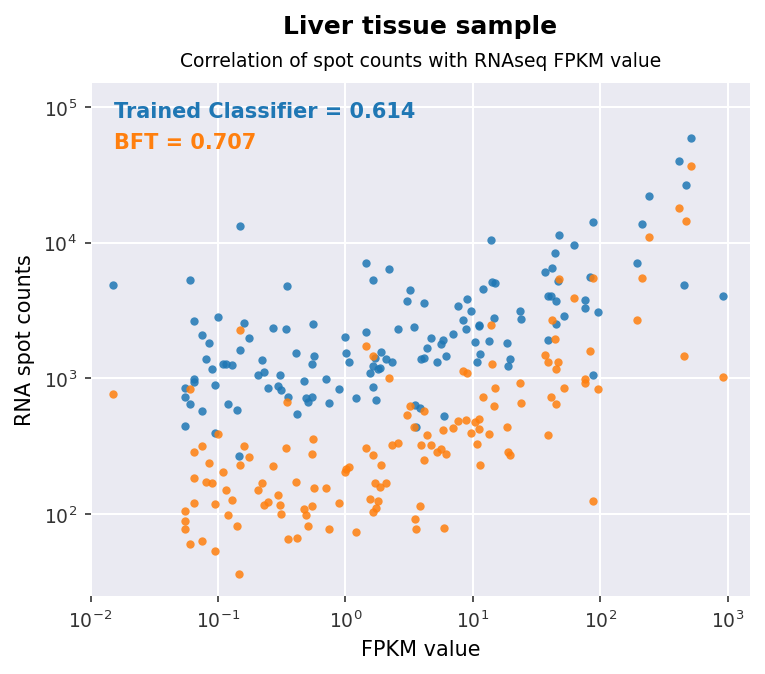

In [40]:
datasets_gs_bft = {
    "model": pooled.rename(columns={"model_counts": "spot_count"}),
    "bft":   pooled.rename(columns={"bft_counts": "spot_count"}),
}

labels_gs_bft = {"model": "Trained Classifier", "bft": "BFT"}

fig2, ax2, correlations_gs_bft = plotFPKMCorrelation(
    datasets_gs_bft,
    colours=colors,
    labels=labels_gs_bft,
    title='Liver tissue sample',
    xlim=(1e-2, 1e3+(1e3/2)),
    ylim=(25, 1e5+(1e5/2)),
)
fig2.savefig(os.path.join(output_dir, 'FPKM_correlation_GS_BFT_lm39_tissue.svg'))

In [41]:
pooled.sum()

FPKM                 4877.31
model_counts       504770.00
bft_counts         161954.00
starfish_counts    989370.00
polaris_counts     874728.00
merlin_counts      103663.00
dtype: float64

In [42]:
pooled.sum().iloc[1]/pooled.sum()

FPKM               103.493524
model_counts         1.000000
bft_counts           3.116749
starfish_counts      0.510193
polaris_counts       0.577059
merlin_counts        4.869336
dtype: float64

In [44]:
pooled.sum()/pooled.sum().iloc[1]

FPKM               0.009662
model_counts       1.000000
bft_counts         0.320847
starfish_counts    1.960041
polaris_counts     1.732924
merlin_counts      0.205367
dtype: float64